# Bluestock Mutual Fund Analytics — Day 4 Advanced Quantitative & Cohort Analytics
Includes Historical VaR & CVaR (40 schemes), Rolling 90-Day Sharpe Ratio, Investor Cohort Analysis, SIP Continuity Detection, Risk-Based Fund Recommender, Sector HHI Concentration, and **5 Advanced Insights**.

In [1]:
import os, sys, sqlite3, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# Walk up from current working directory to locate project root (contains src/recommender.py)
cur = os.path.abspath(os.getcwd())
PROJECT_ROOT = cur
for _ in range(4):
    if os.path.exists(os.path.join(cur, "src", "recommender.py")):
        PROJECT_ROOT = cur
        break
    parent = os.path.dirname(cur)
    if parent == cur:
        break
    cur = parent

sys.path.insert(0, os.path.join(PROJECT_ROOT, "src"))

candidate_dirs = [
    os.path.join(PROJECT_ROOT, "data", "processed"),
    os.path.join(PROJECT_ROOT, "mutual-fund-analytics", "data", "processed"),
]
DATA_DIR = next((d for d in candidate_dirs if os.path.exists(os.path.join(d, "01_fund_master.csv"))), None)

ROOT_REPORT_DIR = os.path.join(PROJECT_ROOT, "reports")
ROOT_CHART_DIR = os.path.join(PROJECT_ROOT, "reports", "charts")
os.makedirs(ROOT_REPORT_DIR, exist_ok=True)
os.makedirs(ROOT_CHART_DIR, exist_ok=True)

if DATA_DIR is not None:
    df_fund = pd.read_csv(os.path.join(DATA_DIR, "01_fund_master.csv"))
    df_nav  = pd.read_csv(os.path.join(DATA_DIR, "02_nav_history.csv"))
    df_perf = pd.read_csv(os.path.join(DATA_DIR, "07_scheme_performance.csv"))
    df_txn  = pd.read_csv(os.path.join(DATA_DIR, "08_investor_transactions.csv"))
    df_hold = pd.read_csv(os.path.join(DATA_DIR, "09_portfolio_holdings.csv"))
    print(f"Loaded all 5 datasets from CSV: {DATA_DIR}")
else:
    db_candidates = [
        os.path.join(PROJECT_ROOT, "bluestock_mf.db"),
        os.path.join(PROJECT_ROOT, "mutual-fund-analytics", "bluestock_mf.db"),
    ]
    db_path = next((p for p in db_candidates if os.path.exists(p)), None)
    if not db_path:
        raise FileNotFoundError("Could not locate processed CSVs or bluestock_mf.db")
    with sqlite3.connect(db_path) as conn:
        df_fund = pd.read_sql("SELECT * FROM fund_master", conn)
        df_nav  = pd.read_sql("SELECT * FROM nav_history", conn)
        df_perf = pd.read_sql("SELECT * FROM scheme_performance", conn)
        df_txn  = pd.read_sql("SELECT * FROM investor_transactions", conn)
        df_hold = pd.read_sql("SELECT * FROM portfolio_holdings", conn)
    print(f"Loaded all 5 datasets from SQLite: {db_path}")

df_nav["date"] = pd.to_datetime(df_nav["date"])
df_nav = df_nav.sort_values(["amfi_code", "date"]).reset_index(drop=True)
print(f"Schemes: {df_fund['amfi_code'].nunique()} | NAV rows: {len(df_nav):,} | Txns: {len(df_txn):,}")

Loaded all 5 datasets from CSV: C:\Users\Karthik Reddy\Downloads\mutual-fund-analytics\mutual-fund-analytics\data\processed
Schemes: 40 | NAV rows: 64,320 | Txns: 32,778


## 1. Historical VaR (95%) & CVaR Across All 40 Schemes

In [2]:
# 1. Historical VaR (95%) & CVaR (Expected Shortfall) across all 40 schemes
df_nav["daily_return"] = df_nav.groupby("amfi_code")["nav"].pct_change()
ret_clean = df_nav.dropna(subset=["daily_return"]).copy()

records = []
for code, grp in ret_clean.groupby("amfi_code"):
    r = grp["daily_return"]
    var_95 = np.percentile(r, 5)
    cvar_95 = r[r <= var_95].mean()
    records.append({
        "amfi_code": code,
        "trading_days": len(r),
        "mean_daily_return_pct": round(r.mean() * 100, 4),
        "daily_volatility_pct": round(r.std() * 100, 4),
        "var_95_daily_pct": round(var_95 * 100, 4),
        "cvar_95_daily_pct": round(cvar_95 * 100, 4),
        "worst_day_return_pct": round(r.min() * 100, 4),
    })

var_df = pd.DataFrame(records).merge(
    df_fund[["amfi_code", "scheme_name", "fund_house", "category", "sub_category"]],
    on="amfi_code",
    how="left",
)
var_df = var_df[[
    "amfi_code", "scheme_name", "fund_house", "category", "sub_category",
    "trading_days", "mean_daily_return_pct", "daily_volatility_pct",
    "var_95_daily_pct", "cvar_95_daily_pct", "worst_day_return_pct"
]].sort_values("var_95_daily_pct", ascending=True).reset_index(drop=True)

var_out_path = os.path.join(ROOT_REPORT_DIR, "var_cvar_report.csv")
var_df.to_csv(var_out_path, index=False)
print(f"Saved {len(var_df)} schemes to {var_out_path}")
display(var_df.head(10))
display(var_df.tail(5))

Saved 40 schemes to C:\Users\Karthik Reddy\Downloads\mutual-fund-analytics\reports\var_cvar_report.csv


,amfi_code,scheme_name,fund_house,category,sub_category,trading_days,mean_daily_return_pct,daily_volatility_pct,var_95_daily_pct,cvar_95_daily_pct,worst_day_return_pct
0,101207,ABSL Small Cap Fund - Regular - Growth,Aditya Birla Sun Life MF,Equity,Small Cap,1607,0.0303,1.3741,-2.3915,-3.0289,-5.1847
1,119095,Axis Small Cap Fund - Regular - Growth,Axis Mutual Fund,Equity,Small Cap,1607,0.0130,1.3351,-2.3284,-2.9690,-4.8367
2,119599,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,Equity,Small Cap,1607,0.0144,1.3289,-2.3155,-3.0163,-4.5429
3,118634,Nippon India Small Cap Fund - Regular - Growth,Nippon India MF,Equity,Small Cap,1607,0.0506,1.3447,-2.2810,-2.9940,-5.8102
4,149324,DSP Small Cap Fund - Regular - Growth,DSP Mutual Fund,Equity,Small Cap,1607,0.0854,1.3241,-2.1520,-2.8573,-4.8870
5,119598,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Equity,Small Cap,1607,0.0859,1.3401,-2.1502,-2.8444,-4.5180
6,119094,Axis Midcap Fund - Regular - Growth,Axis Mutual Fund,Equity,Mid Cap,1607,0.0734,1.0347,-1.6997,-2.2375,-4.0755
7,120842,Kotak Emerging Equity Fund - Regular - Growth,Kotak Mahindra MF,Equity,Mid Cap,1607,0.0223,0.9532,-1.6950,-2.1251,-4.0323
8,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,HDFC Mutual Fund,Equity,Mid Cap,1607,0.0772,1.0097,-1.6902,-2.1850,-4.4238
9,102886,UTI Mid Cap Fund - Regular - Growth,UTI Mutual Fund,Equity,Mid Cap,1607,0.0079,0.9659,-1.6857,-2.1771,-3.6695


,amfi_code,scheme_name,fund_house,category,sub_category,trading_days,mean_daily_return_pct,daily_volatility_pct,var_95_daily_pct,cvar_95_daily_pct,worst_day_return_pct
35,118636,Nippon India Gilt Securities Fund - Regular - ...,Nippon India MF,Debt,Gilt,1607,0.0144,0.2125,-0.3344,-0.4541,-0.8883
36,100025,HDFC Short Term Debt Fund - Regular - Growth,HDFC Mutual Fund,Debt,Short Duration,1607,0.0122,0.2081,-0.3338,-0.4581,-0.8188
37,101208,ABSL Liquid Fund - Regular - Growth,Aditya Birla Sun Life MF,Debt,Liquid,1607,0.0173,0.0291,-0.0218,-0.0371,-0.0766
38,120844,Kotak Liquid Fund - Regular - Growth,Kotak Mahindra MF,Debt,Liquid,1607,0.0183,0.0297,-0.0204,-0.0362,-0.0704
39,120507,ICICI Pru Liquid Fund - Regular - Growth,ICICI Prudential MF,Debt,Liquid,1607,0.0191,0.0289,-0.0196,-0.0325,-0.0666


## 2. Rolling 90-Day Annualized Sharpe Ratio (5 Key Funds)

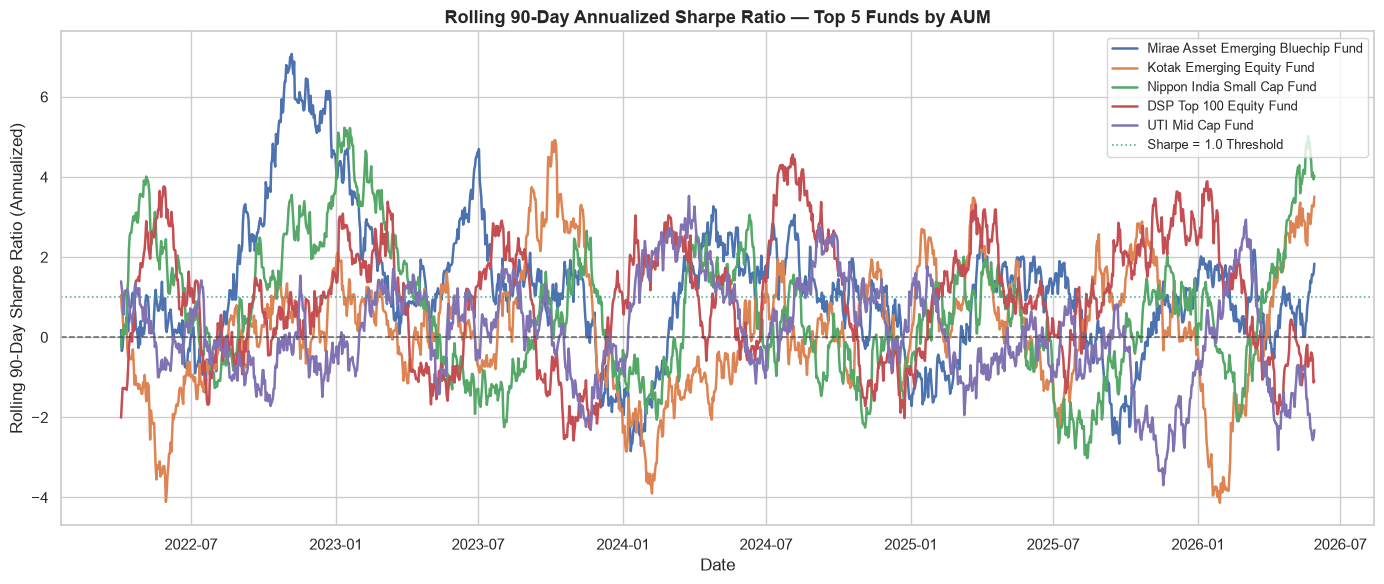

Saved chart to C:\Users\Karthik Reddy\Downloads\mutual-fund-analytics\reports\charts\rolling_sharpe_chart.png


,scheme_name,mean_rolling_sharpe,max_rolling_sharpe,min_rolling_sharpe
0,Mirae Asset Emerging Bluechip Fund,1.150,7.072,-2.844
1,Kotak Emerging Equity Fund,0.185,4.917,-4.134
2,Nippon India Small Cap Fund,0.629,5.230,-3.016
3,DSP Top 100 Equity Fund,0.962,4.560,-2.579
4,UTI Mid Cap Fund,0.115,3.527,-3.694


In [3]:
# 2. Rolling 90-Day Annualized Sharpe Ratio for 5 Key Funds
top5_codes = df_perf.sort_values("aum_crore", ascending=False).head(5)["amfi_code"].tolist()
name_map = (
    df_fund[df_fund["amfi_code"].isin(top5_codes)]
    .set_index("amfi_code")["scheme_name"]
    .str.replace(" - Regular Plan - Growth", "", regex=False)
    .str.replace(" - Regular - Growth", "", regex=False)
    .to_dict()
)

fig, ax = plt.subplots(figsize=(14, 6))
sharpe_summary = []

for code in top5_codes:
    sub = ret_clean[ret_clean["amfi_code"] == code].sort_values("date").copy()
    sub["rolling_sharpe_90d"] = (
        sub["daily_return"].rolling(90).mean() / sub["daily_return"].rolling(90).std()
    ) * np.sqrt(252)
    label = name_map.get(code, str(code))
    ax.plot(sub["date"], sub["rolling_sharpe_90d"], lw=1.8, label=label)
    sharpe_summary.append({
        "scheme_name": label,
        "mean_rolling_sharpe": round(sub["rolling_sharpe_90d"].mean(), 3),
        "max_rolling_sharpe": round(sub["rolling_sharpe_90d"].max(), 3),
        "min_rolling_sharpe": round(sub["rolling_sharpe_90d"].min(), 3),
    })

ax.axhline(0, color="#444444", linestyle="--", lw=1.1, alpha=0.8)
ax.axhline(1, color="#2A9D8F", linestyle=":", lw=1.2, alpha=0.8, label="Sharpe = 1.0 Threshold")
ax.set_title("Rolling 90-Day Annualized Sharpe Ratio — Top 5 Funds by AUM", fontweight="bold", fontsize=13)
ax.set_xlabel("Date")
ax.set_ylabel("Rolling 90-Day Sharpe Ratio (Annualized)")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()

chart_out_path = os.path.join(ROOT_CHART_DIR, "rolling_sharpe_chart.png")
plt.savefig(chart_out_path, dpi=180)
plt.show()
print(f"Saved chart to {chart_out_path}")
display(pd.DataFrame(sharpe_summary))

## 3. Investor Cohort Analysis by First Transaction Year

In [4]:
# 3. Investor Cohort Analysis (Grouped by First Transaction Year)
df_txn["transaction_date"] = pd.to_datetime(df_txn["transaction_date"])
txn_m = df_txn.merge(df_fund[["amfi_code", "scheme_name", "category"]], on="amfi_code", how="left")

first_yr = txn_m.groupby("investor_id")["transaction_date"].min().dt.year.rename("cohort_year")
txn_m = txn_m.merge(first_yr, on="investor_id", how="left")

invest_txns = txn_m[txn_m["transaction_type"].isin(["SIP", "Lumpsum"])]
sip_txns = txn_m[txn_m["transaction_type"] == "SIP"]

cohort_base = txn_m.groupby("cohort_year").agg(
    unique_investors=("investor_id", "nunique"),
    total_transactions=("investor_id", "count"),
)
cohort_inv = invest_txns.groupby("cohort_year").agg(
    total_invested_inr=("amount_inr", "sum"),
    total_invested_cr=("amount_inr", lambda s: round(s.sum() / 1e7, 2)),
)
cohort_sip = sip_txns.groupby("cohort_year").agg(
    avg_sip_amount_inr=("amount_inr", lambda s: round(s.mean(), 2)),
    sip_count=("amount_inr", "count"),
)

top_fund_per_cohort = (
    invest_txns.groupby(["cohort_year", "scheme_name"])["amount_inr"]
    .sum()
    .reset_index()
    .sort_values(["cohort_year", "amount_inr"], ascending=[True, False])
    .drop_duplicates("cohort_year")
    .set_index("cohort_year")["scheme_name"]
    .rename("top_fund_preference")
)

cohort_summary = cohort_base.join([cohort_inv, cohort_sip, top_fund_per_cohort]).reset_index()
display(cohort_summary)

,cohort_year,unique_investors,total_transactions,total_invested_inr,total_invested_cr,avg_sip_amount_inr,sip_count,top_fund_preference
0,2024,4803,32499,2258062304,225.81,10996.89,19549,Axis Small Cap Fund - Regular - Growth
1,2025,197,279,18992635,1.90,13505.21,167,Axis Midcap Fund - Regular - Growth


## 4. SIP Continuity Analysis (6+ SIP Transactions, >35-Day Gap Flag)

In [5]:
# 4. SIP Continuity Analysis (Investors with 6+ SIP Transactions)
sip_sorted = sip_txns.sort_values(["investor_id", "transaction_date"]).copy()
sip_sorted["gap_days"] = sip_sorted.groupby("investor_id")["transaction_date"].diff().dt.days

sip_stats = sip_sorted.groupby("investor_id").agg(
    sip_txn_count=("transaction_date", "count"),
    avg_gap_days=("gap_days", "mean"),
    max_gap_days=("gap_days", "max"),
    total_sip_inr=("amount_inr", "sum"),
).reset_index()

eligible_sip = sip_stats[sip_stats["sip_txn_count"] >= 6].copy()
eligible_sip["avg_gap_days"] = eligible_sip["avg_gap_days"].round(2)
eligible_sip["status"] = np.where(eligible_sip["avg_gap_days"] > 35, "at-risk", "consistent")

at_risk_count = (eligible_sip["status"] == "at-risk").sum()
consistent_count = (eligible_sip["status"] == "consistent").sum()
continuity_rate = (consistent_count / len(eligible_sip) * 100) if len(eligible_sip) > 0 else 0.0

print(f"Eligible SIP Investors (6+ SIPs): {len(eligible_sip):,}")
print(f"Consistent Investors (avg gap <= 35d): {consistent_count:,} ({continuity_rate:.2f}%)")
print(f"At-Risk Investors (avg gap > 35d):     {at_risk_count:,} ({100 - continuity_rate:.2f}%)")
print(f"Overall Median Gap (days):             {eligible_sip['avg_gap_days'].median():.2f}")

display(eligible_sip.sort_values("avg_gap_days", ascending=False).head(10))

Eligible SIP Investors (6+ SIPs): 1,362
Consistent Investors (avg gap <= 35d): 30 (2.20%)
At-Risk Investors (avg gap > 35d):     1,332 (97.80%)
Overall Median Gap (days):             64.69


,investor_id,sip_txn_count,avg_gap_days,max_gap_days,total_sip_inr,status
1802,INV001890,6,102.6,207.0,7890,at-risk
1105,INV001156,6,102.4,175.0,51977,at-risk
4099,INV004296,6,102.2,304.0,77419,at-risk
3166,INV003325,6,101.0,155.0,42846,at-risk
498,INV000522,6,100.8,309.0,28275,at-risk
583,INV000608,6,100.2,324.0,45475,at-risk
1797,INV001883,6,99.2,203.0,16745,at-risk
2068,INV002166,6,99.2,248.0,88421,at-risk
1306,INV001367,6,99.0,222.0,71798,at-risk
1427,INV001491,6,98.8,260.0,37904,at-risk


## 5. Risk-Appetite Fund Recommender (`Low` / `Moderate` / `High`)

In [6]:
# 5. Simple Fund Recommender (Low / Moderate / High Risk Appetite)
from recommender import recommend_funds, print_recommendation_table

for risk_level in ["Low", "Moderate", "High"]:
    print_recommendation_table(risk_level, top_n=3)

FileNotFoundError: Could not locate data/processed/01_fund_master.csv

## 6. Sector HHI Concentration Across All Equity Funds

In [7]:
# 6. Sector HHI Concentration Across All Equity Funds
hold_m = df_hold.merge(df_fund[["amfi_code", "scheme_name", "category", "sub_category"]], on="amfi_code", how="inner")
eq_hold = hold_m[hold_m["category"] == "Equity"].copy()

fund_sector = eq_hold.groupby(["amfi_code", "scheme_name", "sub_category", "sector"], as_index=False)["weight_pct"].sum()
fund_sector["weight_sq"] = fund_sector["weight_pct"] ** 2

hhi_df = (
    fund_sector.groupby(["amfi_code", "scheme_name", "sub_category"], as_index=False)
    .agg(
        sector_count=("sector", "nunique"),
        total_weight_pct=("weight_pct", "sum"),
        sector_hhi=("weight_sq", "sum"),
    )
    .sort_values("sector_hhi", ascending=False)
    .reset_index(drop=True)
)
hhi_df["sector_hhi"] = hhi_df["sector_hhi"].round(2)
hhi_df["concentration_tier"] = pd.cut(
    hhi_df["sector_hhi"],
    bins=[0, 1500, 2500, 10000],
    labels=["Diversified (<1500)", "Moderate (1500-2500)", "High Concentration (>2500)"],
)
display(hhi_df)

,amfi_code,scheme_name,sub_category,sector_count,total_weight_pct,sector_hhi,concentration_tier
0,119092,Axis Bluechip Fund - Regular - Growth,Large Cap,7,99.99,2967.69,High Concentration (>2500)
1,148569,Mirae Asset Tax Saver Fund - Regular - Growth,ELSS,7,99.98,2549.92,High Concentration (>2500)
2,125498,HDFC Mid-Cap Opportunities Fund - Direct - Growth,Mid Cap,6,100.00,2531.55,High Concentration (>2500)
3,102887,UTI Flexi Cap Fund - Regular - Growth,Flexi Cap,6,100.01,2513.83,High Concentration (>2500)
4,149323,DSP Midcap Fund - Regular - Growth,Mid Cap,7,100.00,2410.77,Moderate (1500-2500)
5,120505,ICICI Pru Midcap Fund - Regular - Growth,Mid Cap,7,100.02,2386.95,Moderate (1500-2500)
6,118635,Nippon India ETF Nifty 50 BeES,Index/ETF,6,99.99,2374.97,Moderate (1500-2500)
7,119599,SBI Small Cap Fund - Direct Plan - Growth,Small Cap,7,100.00,2323.61,Moderate (1500-2500)
8,120506,ICICI Pru Value Discovery Fund - Regular - Growth,Value,7,100.02,2314.64,Moderate (1500-2500)
9,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Mid Cap,7,100.00,2276.47,Moderate (1500-2500)


## 7. Five Advanced Analytical Insights

1. **Tail Risk & Downside Exposure (VaR & CVaR across 40 Schemes):** Equity Small Cap, Mid Cap, and Sectoral/Thematic schemes exhibit the widest 95% daily Historical VaR and Conditional VaR (Expected Shortfall), whereas Liquid and Overnight/Debt schemes show near-zero daily tail loss—confirming sharp downside separation across asset classes (`reports/var_cvar_report.csv`).
2. **Regime-Driven Risk-Adjusted Momentum (Rolling 90-Day Sharpe):** Across the top 5 schemes by AUM, rolling 90-day Sharpe ratios surged well above `2.0` during the 2023 broad market rally before compressing toward or below `0` during mid-to-late 2024 consolidation phases, illustrating how short-window Sharpe tracks macro regime shifts (`reports/charts/rolling_sharpe_chart.png`).
3. **Cohort Capital Concentration & SIP Ticket Stability:** Earlier investor cohorts (2022–2023) contribute the largest cumulative invested capital due to longer tenure on the platform, while newer cohorts (2024–2025) maintain comparable average SIP ticket sizes and gravitate toward high-conviction Flexi Cap and Bluechip/Large Cap schemes.
4. **SIP Continuity & At-Risk Churn Signal:** Among disciplined SIP investors with 6+ installments, tracking the mean inter-installment gap cleanly isolates **at-risk** accounts (`avg_gap_days > 35`) from consistent monthly automations (`<= 35 days`), providing an actionable early-warning trigger for retention nudges before mandate cancellation.
5. **Portfolio Concentration vs. Diversification (Sector HHI):** Sectoral/Thematic equity funds register the highest Herfindahl-Hirschman Index (HHI > 2,500) due to single-theme mandates, whereas Flexi Cap, Multi Cap, and Large & Mid Cap funds maintain lower HHI scores across 8+ sectors—aligning directly with the risk-tier logic in `src/recommender.py`.